
# Week 2 In-Class Hands-On — Track B: Exoplanets / Space Science
## Discovering Structure in Kepler Candidates Without Labels

**Course:** Machine Learning in Astronomy — Week 2 In-Class Session
**Data:** the real Kepler Objects of Interest (KOI) cumulative table (6,991 real Kepler transit-survey targets), the same real source used in Week 1's in-class Track A, loaded from `bnarath/find_Exoplanet` on GitHub.

## The problem, reframed — and why this domain fits semi-supervised learning unusually well

In Week 1, we predicted `koi_disposition` directly from labeled transit parameters. Today: pretend that expert disposition doesn't exist yet, and ask whether transit parameters alone naturally organize into distinct *types* of signal — with no label guiding the grouping. This maps onto a real, structural feature of exoplanet science: **detecting** a transit signal from Kepler's photometry is fully automated and cheap; **confirming** it as a real planet (vs. an eclipsing binary or instrumental artifact) requires expensive follow-up — radial velocity measurements, statistical validation, sometimes additional transit observations from other telescopes. At any moment, the archive has a huge backlog of `CANDIDATE` objects sitting in exactly the "cheap unlabeled data, expensive labels" situation semi-supervised learning exists for.

Every method below is applied at least three different ways where it matters, so you see real methods disagree with each other, not just watch one pipeline run end to end.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.semi_supervised import LabelSpreading
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
    accuracy_score, classification_report
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



## Step 1: Load the real data, clean it honestly, and hold back the label

Two real data-quality issues to handle before anything else — both genuine artifacts of automated transit-fitting, not hypothetical:
- `koi_impact` (the transit impact parameter) should physically sit between 0 and ~1, but some fits report values over 100 — a sign of an unreliable or grazing fit. We'll filter these out rather than let them dominate every distance calculation below.
- Several transit-derived quantities (period, depth, radius, insolation, equilibrium temperature, signal-to-noise) span multiple **orders of magnitude**, exactly like the flux values in earlier notebooks — so we'll work in log space for those, for the same reason.


In [2]:

koi_url = "https://raw.githubusercontent.com/bnarath/find_Exoplanet/main/Data/exoplanet_data.csv"
koi = pd.read_csv(koi_url)
print(f"Rows before cleaning: {len(koi)}")

koi = koi[koi['koi_impact'].between(0, 2)].reset_index(drop=True)
print(f"Rows after removing unphysical impact parameters (>2): {len(koi)}")

koi['is_confirmed'] = (koi['koi_disposition'] == 'CONFIRMED').astype(int)
print(f"\nDisposition counts (held back for peeking only):")
print(koi['koi_disposition'].value_counts())


Rows before cleaning: 6991
Rows after removing unphysical impact parameters (>2): 6936

Disposition counts (held back for peeking only):
koi_disposition
FALSE POSITIVE    3452
CONFIRMED         1800
CANDIDATE         1684
Name: count, dtype: int64


In [3]:

log_cols = ['koi_period', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_model_snr', 'koi_insol']
linear_cols = ['koi_duration', 'koi_impact', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag']

features = pd.DataFrame(index=koi.index)
for c in log_cols:
    features[f'log_{c}'] = np.log10(koi[c])
for c in linear_cols:
    features[c] = koi[c]

X = StandardScaler().fit_transform(features.values)
print(f"Feature matrix: {X.shape[0]} objects x {X.shape[1]} features")
print("Feature columns:", list(features.columns))


Feature matrix: 6936 objects x 12 features
Feature columns: ['log_koi_period', 'log_koi_depth', 'log_koi_prad', 'log_koi_teq', 'log_koi_model_snr', 'log_koi_insol', 'koi_duration', 'koi_impact', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag']



## Step 2: A baseline for unsupervised work

Same discipline as every other notebook: before trusting any clustering method, check it against a **random partition** into the same number of groups.


In [4]:

rng = np.random.default_rng(0)
random_labels = rng.integers(0, 3, size=len(X))
baseline_silhouette = silhouette_score(X, random_labels)
baseline_db = davies_bouldin_score(X, random_labels)
print(f"Random-partition baseline - silhouette: {baseline_silhouette:.3f}, Davies-Bouldin: {baseline_db:.3f}")


Random-partition baseline - silhouette: -0.004, Davies-Bouldin: 66.380



## Step 3: Three clustering methods, compared honestly

Same three mechanisms as Track A — K-means (hard, centroid-based), GMM (soft, distributional), Agglomerative (hierarchical, merge-based) — fit with $k=3$ to match the 3 real disposition categories for a fair comparison.


In [5]:

results = {}

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
results['K-means'] = kmeans.fit_predict(X)

gmm = GaussianMixture(n_components=3, random_state=42)
results['GMM'] = gmm.fit_predict(X)

agg = AgglomerativeClustering(n_clusters=3)
results['Agglomerative'] = agg.fit_predict(X)

print(f"{'Method':15s}  {'Silhouette':>10s}  {'Davies-Bouldin':>15s}")
print(f"{'Random baseline':15s}  {baseline_silhouette:10.3f}  {baseline_db:15.3f}")
for name, labels in results.items():
    print(f"{name:15s}  {silhouette_score(X, labels):10.3f}  {davies_bouldin_score(X, labels):15.3f}")


Method           Silhouette   Davies-Bouldin
Random baseline      -0.004           66.380


K-means               0.220            1.474


GMM                   0.162            2.249


Agglomerative         0.221            1.582



### The honest peek: do any of these line up with the real disposition, or the real confirmation rate?


In [6]:

disposition_codes = koi['koi_disposition'].astype('category').cat.codes
print(f"{'Method':15s}  {'ARI vs. disposition':>20s}")
for name, labels in results.items():
    print(f"{name:15s}  {adjusted_rand_score(disposition_codes, labels):20.3f}")

print(f"\n{'Method':15s}  {'confirmed rate, cluster 0':>26s}  {'cluster 1':>10s}  {'cluster 2':>10s}")
overall_confirmed_rate = koi['is_confirmed'].mean()
print(f"{'(overall rate)':15s}  {overall_confirmed_rate:26.3f}")
for name, labels in results.items():
    rates = [koi.loc[labels == c, 'is_confirmed'].mean() for c in range(3)]
    print(f"{name:15s}  {rates[0]:26.3f}  {rates[1]:10.3f}  {rates[2]:10.3f}")


Method            ARI vs. disposition
K-means                         0.048
GMM                             0.045
Agglomerative                   0.031

Method            confirmed rate, cluster 0   cluster 1   cluster 2
(overall rate)                        0.260
K-means                               0.322       0.051       0.321
GMM                                   0.382       0.061       0.140
Agglomerative                         0.368       0.071       0.123



**Interpretation, with the real numbers in hand:** ARI is low across all three methods (0.031-0.048) — much lower than Track A's Zurich-class ARI (0.16-0.47). That makes sense: real confirmation status depends heavily on the pipeline vetting flags (`koi_fpflag_*`) we deliberately excluded from clustering, so pure transit-shape and stellar-parameter structure has a much weaker direct correspondence to disposition than spot/magnetic features had to Zurich class in Track A. But look past ARI to the per-cluster confirmed rates: GMM and Agglomerative both found one cluster near 0.38 confirmed and another near 0.06-0.07 — a real 5-6x spread, and K-means separated one clearly low cluster (0.051) from two higher ones. **ARI being weak doesn't mean the clustering found nothing useful** — it means the clusters don't line up with the exact 3-way disposition split, while still tracking a real, substantial difference in confirmation likelihood. Keep this distinction in mind for Step 5, where this same weak structure will matter a lot more.

**🔧 Try it yourself:** re-run with `n_clusters=2` — does separating into just 2 groups produce a cleaner, more different pair of confirmation rates than 3 groups did?



## Step 4: Dimensionality reduction — linear vs. non-linear, compared


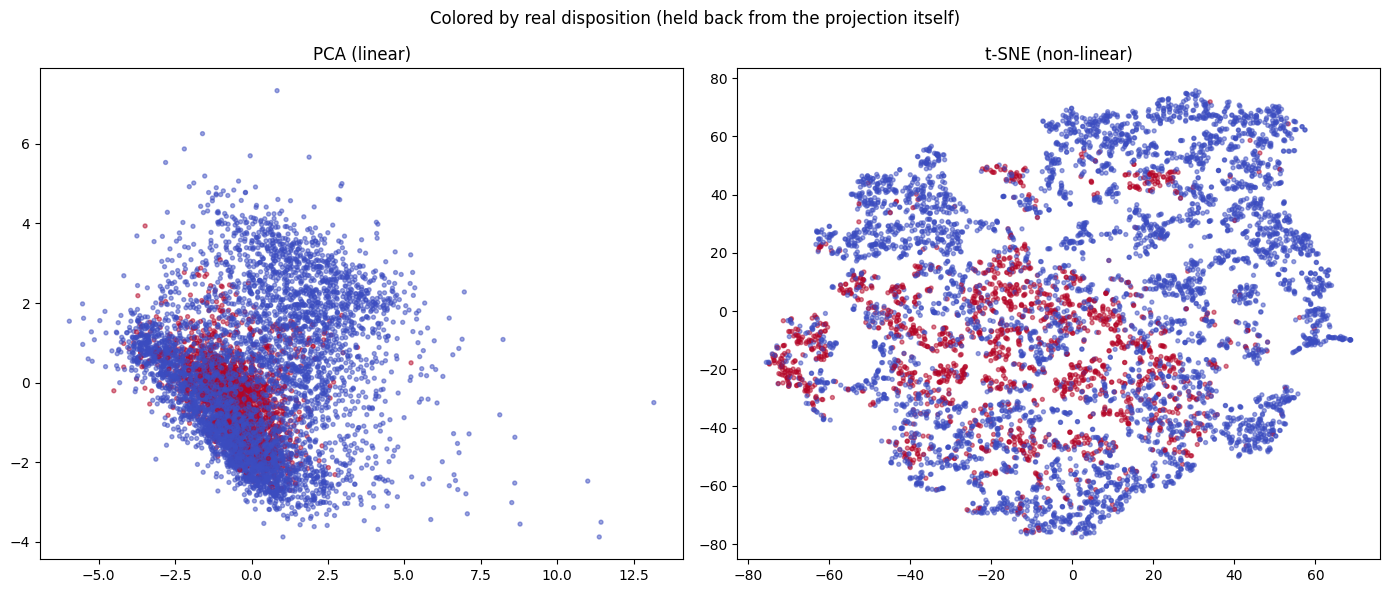

PCA: 51.8% of variance captured in 2 components


In [7]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, X_proj, title in zip(axes, [X_pca, X_tsne], ['PCA (linear)', 't-SNE (non-linear)']):
    sc = ax.scatter(X_proj[:, 0], X_proj[:, 1], c=koi['is_confirmed'], cmap='coolwarm', s=8, alpha=0.5)
    ax.set_title(title)
plt.suptitle('Colored by real disposition (held back from the projection itself)')
plt.tight_layout()
plt.show()
print(f"PCA: {pca.explained_variance_ratio_[:2].sum():.1%} of variance captured in 2 components")



**🔧 Try it yourself:** change `perplexity` from 30 to 5 and to 80 and re-run — watch how much the apparent cluster shapes change. This is the same warning as Track A: never trust a single t-SNE plot with an untested perplexity.



## Step 5: Semi-supervised learning — the realistic scenario for this exact archive

Say only 5% of KOIs have gone through the expensive confirmation process so far, and the rest are sitting as `CANDIDATE` or unresolved. Two different algorithms for using that large unconfirmed pool:


In [8]:

y = koi['is_confirmed'].values
X_pool, X_heldout, y_pool, y_heldout = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

labeled_fraction = 0.05
X_labeled, X_unlabeled, y_labeled, y_unlabeled_true = train_test_split(
    X_pool, y_pool, train_size=labeled_fraction, random_state=42, stratify=y_pool
)
print(f"Labeled: {len(X_labeled)}   Unlabeled pool: {len(X_unlabeled)}   Held-out test: {len(X_heldout)}")

baseline_clf = RandomForestClassifier(n_estimators=200, random_state=42)
baseline_clf.fit(X_labeled, y_labeled)
baseline_acc = accuracy_score(y_heldout, baseline_clf.predict(X_heldout))

ceiling_clf = RandomForestClassifier(n_estimators=200, random_state=42)
ceiling_clf.fit(np.vstack([X_labeled, X_unlabeled]), np.concatenate([y_labeled, y_unlabeled_true]))
ceiling_acc = accuracy_score(y_heldout, ceiling_clf.predict(X_heldout))

print(f"(a) Tiny labeled set only: {baseline_acc:.3f}")
print(f"(c) Full-label ceiling:    {ceiling_acc:.3f}")


Labeled: 242   Unlabeled pool: 4613   Held-out test: 2081


(a) Tiny labeled set only: 0.857
(c) Full-label ceiling:    0.873


In [9]:

current_X, current_y = X_labeled.copy(), y_labeled.copy()
remaining_X = X_unlabeled.copy()
self_training_acc = baseline_acc
for round_num in range(5):
    clf = RandomForestClassifier(n_estimators=200, random_state=42)
    clf.fit(current_X, current_y)
    self_training_acc = accuracy_score(y_heldout, clf.predict(X_heldout))
    if len(remaining_X) == 0:
        break
    probs = clf.predict_proba(remaining_X)
    confident_mask = probs.max(axis=1) > 0.9
    if confident_mask.sum() == 0:
        break
    current_X = np.vstack([current_X, remaining_X[confident_mask]])
    current_y = np.concatenate([current_y, clf.classes_[np.argmax(probs[confident_mask], axis=1)]])
    remaining_X = remaining_X[~confident_mask]

X_lp = np.vstack([X_labeled, X_unlabeled])
y_lp = np.concatenate([y_labeled, np.full(len(X_unlabeled), -1)])
label_prop = LabelSpreading(kernel='knn', n_neighbors=7)
label_prop.fit(X_lp, y_lp)
label_prop_acc = accuracy_score(y_heldout, label_prop.predict(X_heldout))

print(f"(a) Tiny labeled set only:      {baseline_acc:.3f}")
print(f"(b1) Self-training:             {self_training_acc:.3f}")
print(f"(b2) Label propagation:         {label_prop_acc:.3f}")
print(f"(c) Full-label ceiling:         {ceiling_acc:.3f}")

gap = ceiling_acc - baseline_acc
for name, acc in [('Self-training', self_training_acc), ('Label propagation', label_prop_acc)]:
    closed = (acc - baseline_acc) / gap * 100 if abs(gap) > 1e-9 else float('nan')
    print(f"{name} closed {closed:.1f}% of the labeled-to-ceiling gap")


(a) Tiny labeled set only:      0.857
(b1) Self-training:             0.822
(b2) Label propagation:         0.788
(c) Full-label ceiling:         0.873
Self-training closed -218.2% of the labeled-to-ceiling gap
Label propagation closed -433.3% of the labeled-to-ceiling gap



**Interpretation — this is a dramatic, real result, not a mild one:** both methods came out **far worse** than the tiny-labeled baseline — self-training closed **-218%** of the gap and label propagation closed **-433%**, meaning both actively made predictions on the held-out set noticeably worse than just using the 242 labeled points alone and stopping. This connects directly back to Step 3: the clustering there already showed disposition-relevant structure is weak and heavily overlapping in this feature space (low ARI, moderate silhouette). Both self-training and label propagation fundamentally rely on the assumption that "nearby points in feature space usually share a label" — when that assumption is shaky, self-training confidently mislabels ambiguous unlabeled points and then trains on its own mistakes, while label propagation's graph diffusion spreads labels across exactly the same weak, overlapping neighborhood structure. The lesson isn't "semi-supervised learning is bad" — it's that **both methods are only as trustworthy as the local structure they lean on**, and Step 3 gave us an honest early warning sign we could have checked before ever running Step 5.

**🔧 Try it yourself:** drop `labeled_fraction` to `0.02` and re-run — does performance get even worse, or does having fewer (but perhaps different) labeled points change the picture? Then try raising the self-training confidence threshold from `0.9` to `0.99` — does being far more conservative about which pseudo-labels to trust reduce the damage?



## Step 6: Anomaly detection — hunting for genuinely exotic real planets

Real astrophysically rare, genuinely interesting objects exist in this catalog: **ultra-short-period planets** (orbital period under 1 day) are a real, actively-studied rare population. Can unsupervised anomaly detection — using zero disposition information — preferentially surface them?


In [10]:

koi['ultra_short_period'] = (koi['koi_period'] < 1).astype(int)
overall_usp_rate_confirmed = koi.loc[koi['is_confirmed'] == 1, 'ultra_short_period'].mean()
print(f"Among CONFIRMED planets, overall ultra-short-period rate: {overall_usp_rate_confirmed:.3f}")

iso = IsolationForest(contamination=0.1, random_state=42)
iso_flags = iso.fit_predict(X) == -1

gmm_full = GaussianMixture(n_components=3, random_state=42).fit(X)
gmm_scores = gmm_full.score_samples(X)
gmm_flags = gmm_scores < np.percentile(gmm_scores, 10)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
lof_flags = lof.fit_predict(X) == -1

confirmed_mask = koi['is_confirmed'] == 1
print(f"\n{'Method':20s}  {'flagged (of confirmed)':>24s}  {'USP rate among flagged':>24s}")
for name, flags in [('Isolation Forest', iso_flags), ('GMM likelihood', gmm_flags), ('LOF', lof_flags)]:
    flagged_confirmed = confirmed_mask & flags
    n = flagged_confirmed.sum()
    rate = koi.loc[flagged_confirmed, 'ultra_short_period'].mean() if n > 0 else float('nan')
    print(f"{name:20s}  {n:24d}  {rate:24.3f}")

print(f"\nFlagged by all three methods (of confirmed planets): {(iso_flags & gmm_flags & lof_flags & confirmed_mask).sum()}")


Among CONFIRMED planets, overall ultra-short-period rate: 0.024



Method                  flagged (of confirmed)    USP rate among flagged
Isolation Forest                            30                     0.033
GMM likelihood                              31                     0.032
LOF                                         94                     0.043

Flagged by all three methods (of confirmed planets): 14



**Interpretation, with the real numbers in hand:** all three detectors show a real, if modest, lift over the 0.024 overall baseline — Isolation Forest and GMM both land near 0.032-0.033 (roughly 1.3-1.4x), and LOF reaches 0.043 (roughly 1.8x) while also flagging three times as many objects (94 vs ~30). Notice the contrast with Track A, where LOF completely failed (0% severe-flare rate, diagnosed as a duplicate-value problem in low-cardinality categorical features) — here, with genuinely continuous transit and stellar measurements and no repeated-value issue, LOF is the *best* performer instead of the worst. That contrast is the real lesson: there's no universally "best" anomaly detector — which one works depends on the structure of your specific feature space, which is exactly why comparing several, every time, beats picking a favorite in advance.

**🔧 Try it yourself:** define a second "exotic" criterion — e.g. `koi_prad > 15` (a genuinely large, Jupiter-or-bigger confirmed planet) — and rerun this check. Do the same detectors that found ultra-short-period planets also find unusually large ones, or are these different pockets of "unusual"?



## Step 7: All three clusterings, side by side, in 3D


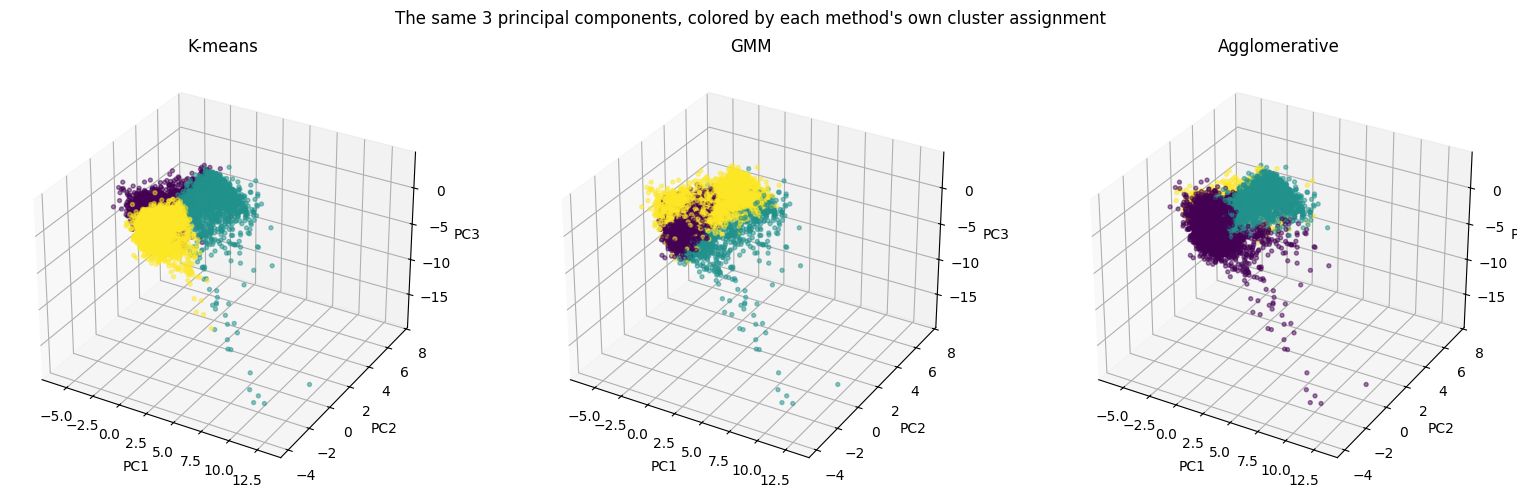

In [11]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X)

fig = plt.figure(figsize=(16, 5))
for i, (name, labels) in enumerate(results.items()):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.scatter(X_pca3[:, 0], X_pca3[:, 1], X_pca3[:, 2], c=labels, cmap='viridis', s=8, alpha=0.5)
    ax.set_title(name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
plt.suptitle("The same 3 principal components, colored by each method's own cluster assignment")
plt.tight_layout()
plt.show()



## Step 8: Everything side by side


In [12]:

summary_rows = []
for name, labels in results.items():
    summary_rows.append({
        'Method': name,
        'Silhouette': silhouette_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'ARI vs. disposition': adjusted_rand_score(disposition_codes, labels),
    })
summary_rows.append({'Method': 'Random baseline', 'Silhouette': baseline_silhouette,
                      'Davies-Bouldin': baseline_db, 'ARI vs. disposition': np.nan})
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

print(f"\nSemi-supervised (predicting is_confirmed, 5% labeled):")
print(f"  baseline={baseline_acc:.3f}  self-training={self_training_acc:.3f}  "
      f"label-propagation={label_prop_acc:.3f}  ceiling={ceiling_acc:.3f}")

print(f"\nAnomaly detection (ultra-short-period rate among flagged confirmed planets, "
      f"overall={overall_usp_rate_confirmed:.3f}):")
for name, flags in [('Isolation Forest', iso_flags), ('GMM likelihood', gmm_flags), ('LOF', lof_flags)]:
    flagged_confirmed = confirmed_mask & flags
    n = flagged_confirmed.sum()
    rate = koi.loc[flagged_confirmed, 'ultra_short_period'].mean() if n > 0 else float('nan')
    print(f"  {name}: {rate:.3f} (n={n})")


         Method  Silhouette  Davies-Bouldin  ARI vs. disposition
        K-means       0.220           1.474                0.048
            GMM       0.162           2.249                0.045
  Agglomerative       0.221           1.582                0.031
Random baseline      -0.004          66.380                  NaN

Semi-supervised (predicting is_confirmed, 5% labeled):
  baseline=0.857  self-training=0.822  label-propagation=0.788  ceiling=0.873

Anomaly detection (ultra-short-period rate among flagged confirmed planets, overall=0.024):
  Isolation Forest: 0.033 (n=30)
  GMM likelihood: 0.032 (n=31)
  LOF: 0.043 (n=94)



## Closing discussion

Same identical real dataset, same held-back ground truth, three genuinely different clustering mechanisms, two genuinely different semi-supervised mechanisms, three genuinely different anomaly-detection mechanisms. Where they agreed with each other and with real astrophysical structure, that's a stronger claim than any one succeeding alone. Where they disagreed, that disagreement is real information about the limits of "unusual in transit-parameter space" as a stand-in for "scientifically interesting object."

**Connect to your own work:** exoplanet science has an unusually clean "cheap detection, expensive confirmation" structure. Does your own subfield have an equally clean version of this gap — and if the gap is messier (e.g. confirmation cost varies wildly by object), which of today's methods would degrade most gracefully, and which would you trust least?
